# Noisy-DQN, Noisy-A3C и Noisy-PPO

Курсовая работа по МГМО. Горбунов Иван Олегович, ИУ6-74б.
Руководитель — Кудрявцев Сергей Александрович.

Ноутбук закрывает модели индивидуального задания: Noisy-DQN без ε-жадного
выбора, Noisy-A3C, Noisy-PPO, независимый и факторизованный шум, динамику σ,
скорость и стабильность обучения. Подробная серия DQN сохранена в
`02_final_study.ipynb`. Здесь подробно проверяется дополнительная серия A3C/PPO.

Всего без пилота: 200 обучений, 26 млн переходов. Из них 120 обучений и 15 млн
переходов относятся к A3C/PPO. Ни один запуск не исключается по награде.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display
from noisynets.policy_analysis import load_policy_study, summarize_policy, make_figures, verify_policy, LABELS
from noisynets.actorcritic import PolicyConfig, create_model
from noisynets.policy_networks import PolicyNoisyLinear

ROOT=Path.cwd()
if not (ROOT/'configs/policy_study.json').exists(): ROOT=ROOT.parent
assert (ROOT/'configs/policy_study.json').exists()
OUT=ROOT/'results/policy_analysis';OUT.mkdir(parents=True,exist_ok=True)
torch.set_num_threads(1)
pd.set_option('display.max_rows',100)
pd.set_option('display.float_format',lambda x:f'{x:.3f}')
runs,curves,manifest=load_policy_study(ROOT/'results/policy',ROOT/'configs/policy_study.json')
summary=summarize_policy(runs)
assert len(runs)==120 and summary['training_steps']==15_000_000
print('120 завершенных обучений, 15 000 000 переходов дополнительной серии')

120 завершенных обучений, 15 000 000 переходов дополнительной серии


## 1. Протокол

До запусков зафиксирован `configs/policy_study.json`. В каждой среде сравниваются
A3C, Noisy-A3C с независимым и факторизованным шумом, PPO и два Noisy-PPO.
Используются seed 200–209. Валидация — 10 эпизодов на seed 55000–55009,
отложенная оценка — 30 эпизодов на 65000–65029. Чекпойнт всегда последний.

Основной режим — sampling действий из categorical-политики. У шумовых моделей
ε обновляется каждые 20 шагов оценки A3C или 128 шагов PPO. Дополнительно
проверяются sampling и argmax по средним весам. Это разные политики.

In [2]:
display(pd.DataFrame([{ 'Среда':e['config']['env'],'Бюджет':e['config']['steps'],
    'Скрытый слой':e['config']['hidden'],'Число условий':len(e['conditions']),
    'σ₀':e['config']['sigma0'],'Потоков/сред':e['config']['workers']}
    for e in manifest['environments']]))
display(pd.DataFrame(manifest['environments'][0]['conditions']))

,Среда,Бюджет,Скрытый слой,Число условий,σ₀,Потоков/сред
0,CartPole-v1,100000,64,6,0.100,4
1,Acrobot-v1,150000,128,6,0.100,4


,key,algorithm,learning_rate,entropy_coef,generation
0,a3c,a3c,0.000,0.010,independent
1,noisy_a3c_independent,noisy-a3c,0.000,0.000,independent
2,noisy_a3c_factorized,noisy-a3c,0.000,0.000,factorized
3,ppo,ppo,0.000,0.010,factorized
4,noisy_ppo_factorized,noisy-ppo,0.000,0.000,factorized
5,noisy_ppo_independent,noisy-ppo,0.000,0.000,independent


## 2. Что реализовано

**DQN** обучает Q-функцию по replay и target network. Его поведение ε-жадное.
В **Noisy-DQN** выбор действия жадный относительно возмущённой Q-функции,
а параметры μ и σ обучаются совместно. Исходные 80 запусков не изменены.

**A3C** использует четыре конкурентных actor-learner с собственными средами
и локальными сетями. После копирования общих параметров каждый независимо
собирает rollout до 20 шагов, строит n-step-возврат и градиент actor/critic.
Только копирование и применение Adam атомарны. Пока поток считает градиент,
другой может обновить общую сеть. Это регистрируется как staleness.
Синхронизация всех потоков выполняется только на границах оценки.

При истинном окончании bootstrap нулевой. При TimeLimit используется ценность
последнего наблюдения до reset. Actor использует преимущество G−V, отсоединённое
от графа; critic минимизирует половину квадрата ошибки. У базового A3C
есть entropy bonus β=0,01, у Noisy-A3C β=0. Sampling действий сохраняется.
В Noisy-A3C одна реализация шума фиксирована на rollout и обратный проход.

**PPO** собирает данные четырёх сред, затем выполняет четыре эпохи по minibatch64.
Применяются GAE(λ=0,95), clip0,2 и ограничение нормы градиента0,5.
В **Noisy-PPO** старая и текущая вероятность условны на одинаковом ε:

\[
\rho_t(\theta,\varepsilon)=
\frac{\pi_\theta(a_t\mid s_t,\varepsilon)}
{\pi_{old}(a_t\mid s_t,\varepsilon)}.
\]

Распределение ε не зависит от θ, поэтому сокращается в совместном отношении.
Шум не пересэмплируется до завершения всех эпох данного rollout. До первого
обновления код проверяет log-ratio≈0. Коэффициенты μ и σ при оптимизации меняются.
Noisy-PPO — описанная здесь интеграция для курсовой, а не модель из статьи2018г.

In [3]:
torch.manual_seed(82);a=create_model(PolicyConfig(),4,2)
torch.manual_seed(82);b=create_model(PolicyConfig(algorithm='noisy-ppo'),4,2)
a.eval();b.eval();x=torch.randn(10,4)
for left,right in zip(a(x),b(x)): torch.testing.assert_close(left,right)
print('Средние начальные параметры baseline/noisy совпадают')
display(b)

Средние начальные параметры baseline/noisy совпадают


ActorCritic(
  (input): Linear(in_features=4, out_features=64, bias=True)
  (hidden): PolicyNoisyLinear()
  (actor): PolicyNoisyLinear()
  (critic): PolicyNoisyLinear()
)

## 3. Два способа генерации шума

Независимый Gaussian-шум задаёт отдельный N(0,1) для каждого веса и смещения:
pq+q случайных значений. Факторизованный вариант использует p+q значений,
преобразование sign(x)√|x| и внешнее произведение. Ранг1 относится к ε весов,
а не обязательно к σ⊙ε. Равный σ₀ не означает одинаковую дисперсию возмущения.

In [4]:
rows=[]
for generation in ['independent','factorized']:
    layer=PolicyNoisyLinear(40,30,generation=generation)
    layer.reset_noise(torch.Generator().manual_seed(44))
    rows.append({'Генератор':generation,'Ранг ε':int(torch.linalg.matrix_rank(layer.weight_epsilon)),
                 'Среднее ε':float(layer.weight_epsilon.mean()),'SD ε':float(layer.weight_epsilon.std())})
display(pd.DataFrame(rows))

,Генератор,Ранг ε,Среднее ε,SD ε
0,independent,30,0.018,0.995
1,factorized,1,-0.010,0.821


## 4. Качество и динамика обучения

Единица наблюдения — обучение с отдельным seed. Итог каждой модели — среднее
30 отложенных эпизодов. Среднее и SD ниже рассчитаны по десяти моделям.
AUC — трапецеидальная площадь по 11 валидационным точкам, делённая на бюджет.
Среда CartPole имеет положительный возврат, Acrobot — отрицательный; их шкалы
не усредняются. Полоса на графике — одно SD, не доверительный интервал.

,environment,label,final_mean,final_seed_sd,median,auc_mean,success_rate
0,acrobot,A3C,-498.690,1.704,-499.383,-494.145,0.017
1,acrobot,Noisy-A3C факторизованный,-496.717,3.961,-498.050,-497.294,0.050
2,acrobot,Noisy-A3C независимый,-495.797,6.217,-498.650,-495.407,0.060
3,acrobot,Noisy-PPO факторизованный,-378.043,196.381,-500.000,-440.251,0.300
4,acrobot,Noisy-PPO независимый,-459.170,129.116,-500.000,-478.297,0.100
5,acrobot,PPO,-168.597,154.880,-92.817,-368.228,0.870
6,cartpole,A3C,49.613,8.535,48.350,34.662,0.000
7,cartpole,Noisy-A3C факторизованный,49.167,4.105,49.700,38.252,0.000
8,cartpole,Noisy-A3C независимый,48.100,6.940,50.433,38.365,0.000
9,cartpole,Noisy-PPO факторизованный,107.977,46.484,105.733,90.418,0.003


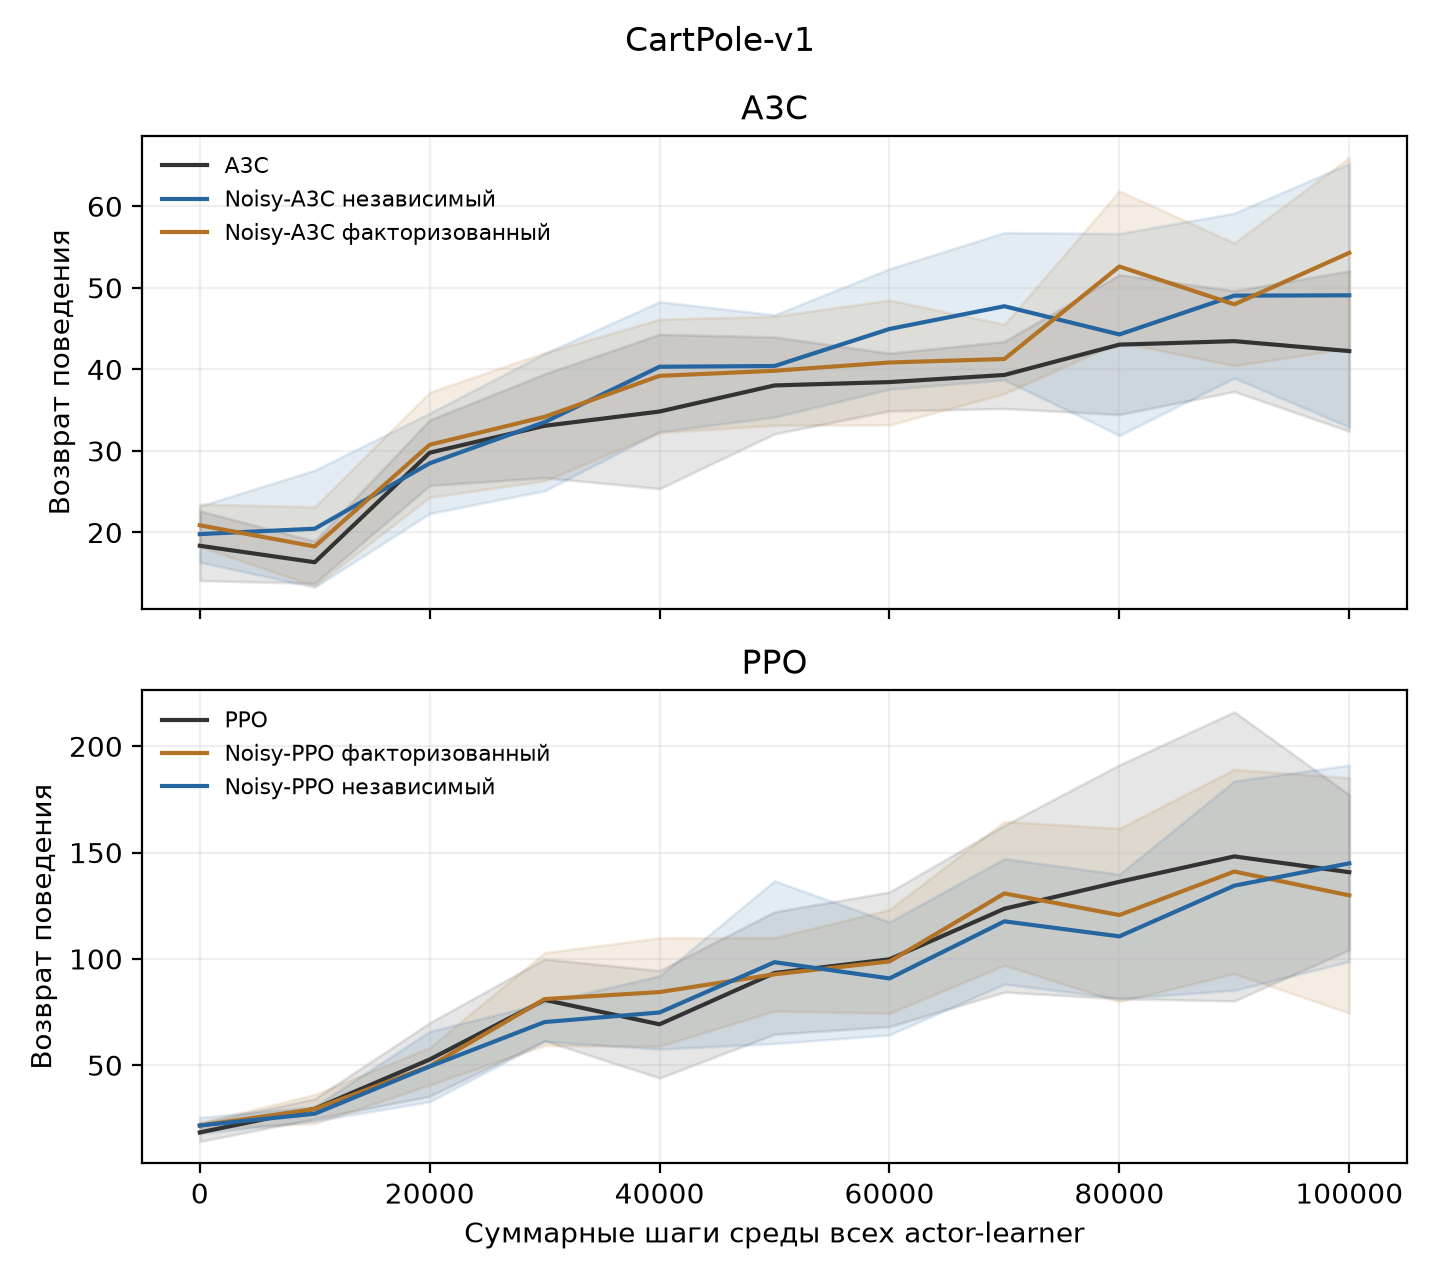

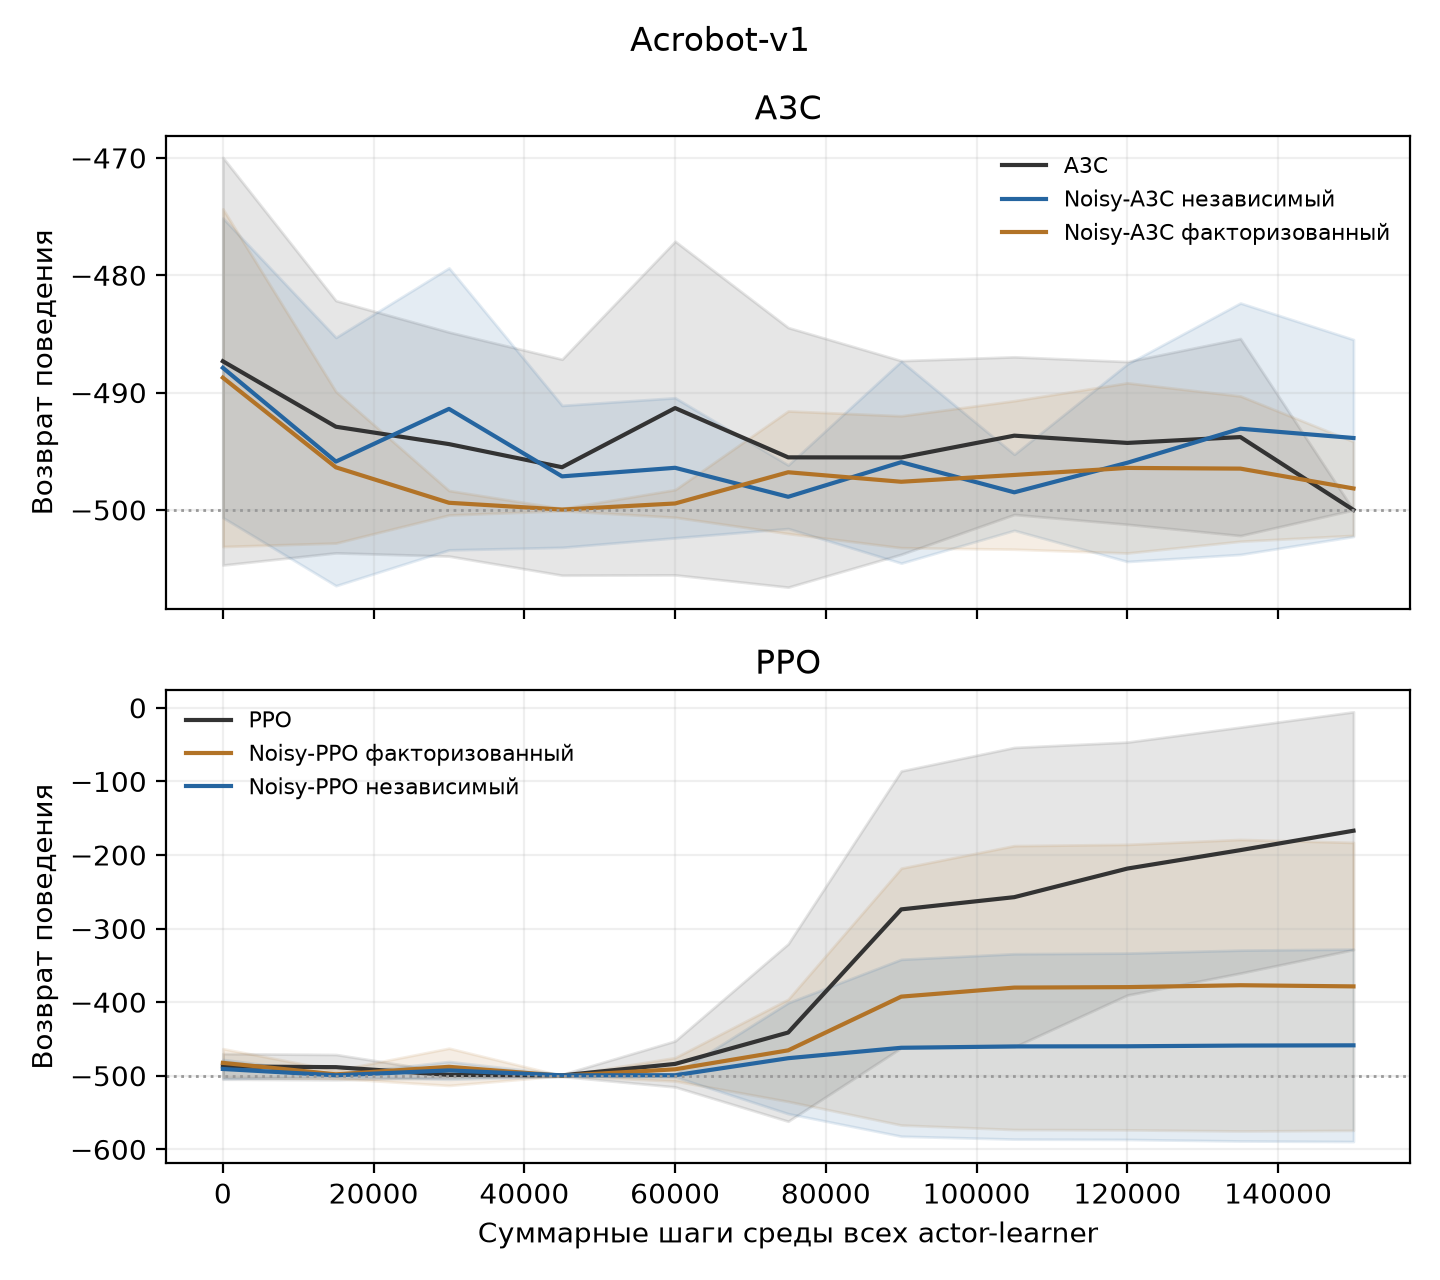

In [5]:
conditions=pd.DataFrame(summary['conditions'])
display(conditions[['environment','label','final_mean','final_seed_sd','median','auc_mean','success_rate']])
make_figures(runs,curves,OUT/'figures')
for env in ['cartpole','acrobot']: display(Image(filename=str(OUT/'figures'/f'{env}_learning.png')))

## 5. Парные сравнения и генераторы

Все интервалы описательные, без поправки на множественные сравнения:
20 000 парных bootstrap-перевыборок, seed7241. Пары сохраняют общий seed
и начальные μ, но не общий опыт. В A3C дополнительно различается порядок потоков.
Нулевое значение внутри интервала не доказывает эквивалентности.

In [6]:
comparisons=pd.DataFrame(summary['comparisons'])
display(comparisons[['environment','condition','reference','metric','mean_difference','ci95_low','ci95_high']])
display(pd.DataFrame(summary['generation_comparisons'])[['environment','family','metric','mean_difference','ci95_low','ci95_high']])

,environment,condition,reference,metric,mean_difference,ci95_low,ci95_high
0,acrobot,noisy_a3c_factorized,a3c,final_mean,1.973,0.190,4.077
1,acrobot,noisy_a3c_factorized,a3c,auc_mean,-3.150,-5.884,-0.692
2,acrobot,noisy_a3c_independent,a3c,final_mean,2.893,-0.237,6.910
3,acrobot,noisy_a3c_independent,a3c,auc_mean,-1.263,-5.874,3.372
4,acrobot,noisy_ppo_factorized,ppo,final_mean,-209.447,-365.660,-37.132
5,acrobot,noisy_ppo_factorized,ppo,auc_mean,-72.023,-153.453,19.668
6,acrobot,noisy_ppo_independent,ppo,final_mean,-290.573,-406.640,-122.495
7,acrobot,noisy_ppo_independent,ppo,auc_mean,-110.069,-177.229,-25.971
8,cartpole,noisy_a3c_factorized,a3c,final_mean,-0.447,-7.163,5.650
9,cartpole,noisy_a3c_factorized,a3c,auc_mean,3.591,2.338,4.957


,environment,family,metric,mean_difference,ci95_low,ci95_high
0,cartpole,a3c,final_mean,-1.067,-6.313,3.203
1,cartpole,a3c,auc_mean,0.112,-2.103,2.443
2,cartpole,ppo,final_mean,32.417,-9.987,71.927
3,cartpole,ppo,auc_mean,-4.733,-12.317,2.682
4,acrobot,a3c,final_mean,0.920,-2.613,5.613
5,acrobot,a3c,auc_mean,1.887,-0.453,4.530
6,acrobot,ppo,final_mean,-81.127,-203.650,1.247
7,acrobot,ppo,auc_mean,-38.046,-92.104,-0.412


## 6. Скорость достижения порога и стабильность

Пороги определены до запусков: validation475 для CartPole, −100 для Acrobot.
Недостижение — цензурированное наблюдение. Медиана времени среди достигших
показывается вместе с числом достигших, поэтому быстрый успех одного seed
не трактуется как успех всего метода. Это критерий по сетке оценок, а не
математическое доказательство сходимости. SD последних пяти оценок описывает
колебания внутри запуска, включая случайность контрольных эпизодов.

In [7]:
display(conditions[['environment','label','threshold_reached',
                   'threshold_step_median_among_reached','tail_validation_sd','final_seed_sd']])

,environment,label,threshold_reached,threshold_step_median_among_reached,tail_validation_sd,final_seed_sd
0,acrobot,A3C,0,NaN,6.486,1.704
1,acrobot,Noisy-A3C факторизованный,0,NaN,3.184,3.961
2,acrobot,Noisy-A3C независимый,0,NaN,4.249,6.217
3,acrobot,Noisy-PPO факторизованный,3,105000.000,6.750,196.381
4,acrobot,Noisy-PPO независимый,1,120000.000,1.299,129.116
5,acrobot,PPO,7,120000.000,48.657,154.880
6,cartpole,A3C,0,NaN,6.240,8.535
7,cartpole,Noisy-A3C факторизованный,0,NaN,8.792,4.105
8,cartpole,Noisy-A3C независимый,0,NaN,9.867,6.940
9,cartpole,Noisy-PPO факторизованный,0,NaN,41.866,46.484


## 7. Масштаб шума и режим применения модели

В σ не заложено принудительное затухание. Показана фактическая динамика
среднего модуля весовых коэффициентов, среднее и SD по десяти seed.
Масштабы смещений также сохранены в исходных CSV. Изменение σ не измеряет
напрямую исследованное пространство состояний. В режиме eval шум отключается.

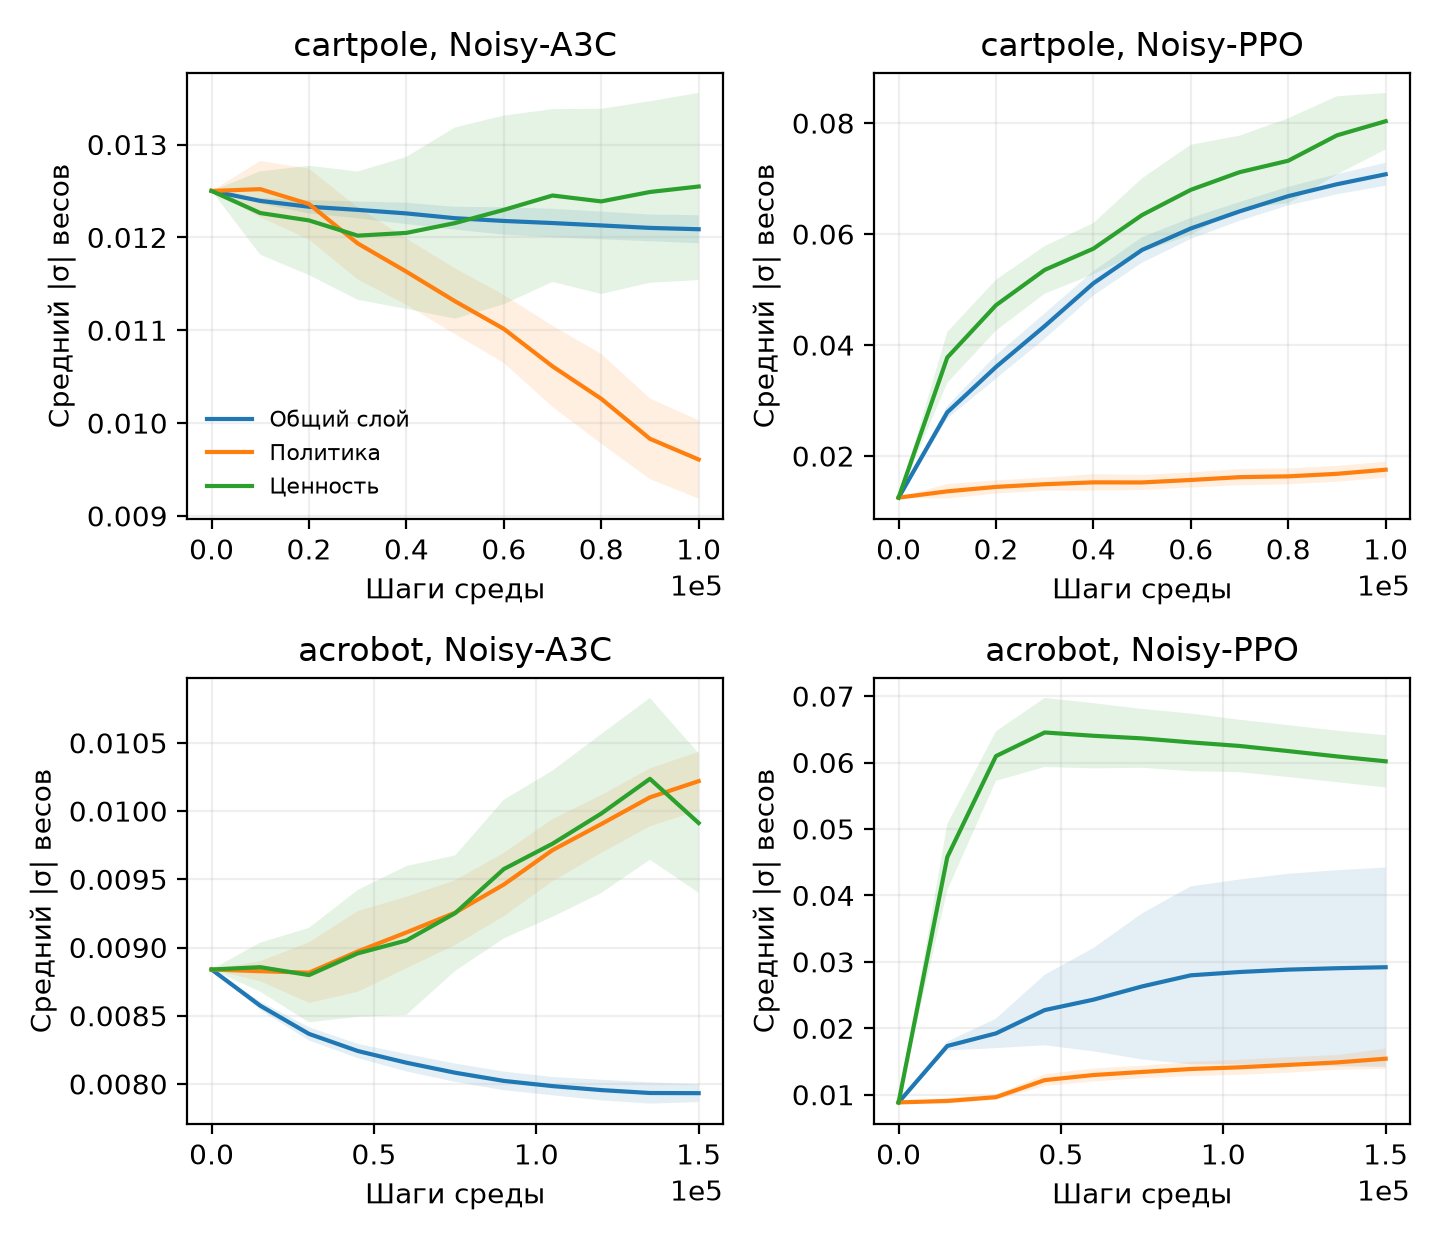

,environment,label,final_mean,mean_sampled,mean_greedy
0,acrobot,A3C,-498.690,-498.690,-500.000
1,acrobot,Noisy-A3C факторизованный,-496.717,-498.397,-500.000
2,acrobot,Noisy-A3C независимый,-495.797,-497.317,-500.000
3,acrobot,Noisy-PPO факторизованный,-378.043,-376.920,-374.537
4,acrobot,Noisy-PPO независимый,-459.170,-458.893,-458.370
5,acrobot,PPO,-168.597,-168.597,-166.607
6,cartpole,A3C,49.613,49.613,160.283
7,cartpole,Noisy-A3C факторизованный,49.167,49.827,266.840
8,cartpole,Noisy-A3C независимый,48.100,52.393,198.253
9,cartpole,Noisy-PPO факторизованный,107.977,107.033,237.217


,environment,condition,mean_difference,ci95_low,ci95_high
0,acrobot,noisy_a3c_factorized,1.680,-0.700,4.007
1,acrobot,noisy_a3c_independent,1.520,-0.770,3.717
2,acrobot,noisy_ppo_factorized,-1.123,-2.887,0.193
3,acrobot,noisy_ppo_independent,-0.277,-0.830,0.000
4,cartpole,noisy_a3c_factorized,-0.660,-5.020,3.483
5,cartpole,noisy_a3c_independent,-4.293,-8.490,-0.337
6,cartpole,noisy_ppo_factorized,0.943,-12.580,17.098
7,cartpole,noisy_ppo_independent,2.253,-7.143,10.843


A3C: у всех60 запусков есть асинхронные устаревшие градиенты; max= 10
PPO: максимальная ошибка начального log-ratio: 2.384185791015625e-06


In [8]:
display(Image(filename=str(OUT/'figures/sigma_weights.png')))
display(conditions[['environment','label','final_mean','mean_sampled','mean_greedy']])
display(pd.DataFrame(summary['mode_comparisons'])[['environment','condition','mean_difference','ci95_low','ci95_high']])
async_rows=[];ratio_errors=[]
for marker in sorted((ROOT/'results/policy').glob('*/*/seed_*/COMPLETE')):
    meta=json.loads((marker.parent/'metadata.json').read_text())
    if 'max_staleness' in meta: async_rows.append(meta['max_staleness'])
    if 'max_initial_logratio_error' in meta: ratio_errors.append(meta['max_initial_logratio_error'])
assert len(async_rows)==60 and min(async_rows)>0
assert len(ratio_errors)==60 and max(ratio_errors)<2e-5
print('A3C: у всех60 запусков есть асинхронные устаревшие градиенты; max=',max(async_rows))
print('PPO: максимальная ошибка начального log-ratio:',max(ratio_errors))

## 8. Повторная оценка всех сохранённых моделей

Сравниваются все награды, длины, seed и признаки terminated/truncated.
Проверяются120 checkpoint и9600 эпизодов во всех предусмотренных режимах.
Это проверка оценки, а не повторное обучение асинхронных моделей.

In [9]:
verification=verify_policy(ROOT/'results/policy')
verification.to_csv(OUT/'checkpoint_verification.csv',index=False)
assert len(verification)==320 and verification.n_episodes.sum()==9600
display(verification.groupby(['environment','mode'],as_index=False).agg(
    моделей=('matches','size'),эпизодов=('n_episodes','sum'),совпали=('matches','all')))
print('Все120 checkpoint и9600 эпизодов совпали')

,environment,mode,моделей,эпизодов,совпали
0,acrobot,behaviour,60,1800,True
1,acrobot,mean_greedy,60,1800,True
2,acrobot,mean_sampled,40,1200,True
3,cartpole,behaviour,60,1800,True
4,cartpole,mean_greedy,60,1800,True
5,cartpole,mean_sampled,40,1200,True


Все120 checkpoint и9600 эпизодов совпали


## 9. Связь с серией DQN и ограничения

Серия DQN использует seed100–109 и иной протокол оценки. В ней Noisy-DQN
не показал превосходства по средним весам; на Acrobot включение шума резко
изменяет результат. Детальная статистика доступна в предыдущем ноутбуке.
Показатели разных семейств не образуют общий парный тест и не усредняются.

Noisy-A3C/PPO отличаются от baseline и шумовыми слоями, и отключённым
энтропийным бонусом. Поэтому сравнивается определённый вариант алгоритма,
а отдельное причинное влияние каждого компонента не выделено.
Обучение A3C не является побитово воспроизводимым из-за порядка потоков;
фиксированные checkpoint оцениваются воспроизводимо. Оценка использует
одну последовательность случайного шума на seed старта. Две среды с плотной
наградой не позволяют обобщить вывод на Atari и редкие события.

In [10]:
dqn=pd.read_csv(ROOT/'results/final_analysis/conditions.csv')
display(dqn.loc[dqn.condition.isin(['dqn','noisy']),
               ['environment','condition','final_mean','final_seed_sd','stochastic_mean']])
conclusions=[]
for row in summary['comparisons']:
    if row['metric']!='final_mean':continue
    outcome=('интервал целиком положителен' if row['ci95_low']>0 else
             'интервал целиком отрицателен' if row['ci95_high']<0 else 'интервал включает ноль')
    conclusions.append(f"{row['environment']}, {LABELS[row['condition']]}: Δ={row['mean_difference']:.2f}, "
                       f"95%[{row['ci95_low']:.2f};{row['ci95_high']:.2f}]; {outcome}.")
display(Markdown((chr(10)*2).join(conclusions)))

,environment,condition,final_mean,final_seed_sd,stochastic_mean
0,acrobot,dqn,-186.703,168.238,NaN
1,acrobot,noisy,-459.273,128.789,-195.663
6,cartpole,dqn,139.883,51.072,NaN
7,cartpole,noisy,131.137,80.038,129.697


acrobot, Noisy-A3C факторизованный: Δ=1.97, 95%[0.19;4.08]; интервал целиком положителен.

acrobot, Noisy-A3C независимый: Δ=2.89, 95%[-0.24;6.91]; интервал включает ноль.

acrobot, Noisy-PPO факторизованный: Δ=-209.45, 95%[-365.66;-37.13]; интервал целиком отрицателен.

acrobot, Noisy-PPO независимый: Δ=-290.57, 95%[-406.64;-122.50]; интервал целиком отрицателен.

cartpole, Noisy-A3C факторизованный: Δ=-0.45, 95%[-7.16;5.65]; интервал включает ноль.

cartpole, Noisy-A3C независимый: Δ=-1.51, 95%[-8.54;4.64]; интервал включает ноль.

cartpole, Noisy-PPO факторизованный: Δ=-38.09, 95%[-78.34;-0.08]; интервал целиком отрицателен.

cartpole, Noisy-PPO независимый: Δ=-5.67, 95%[-33.37;23.87]; интервал включает ноль.

## Источники

1. Fortunato et al. [Noisy Networks for Exploration](https://arxiv.org/abs/1706.10295).
2. Mnih et al. [Asynchronous Methods for Deep Reinforcement Learning](https://arxiv.org/abs/1602.01783).
3. Schulman et al. [Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347).
4. Schulman et al. [Generalized Advantage Estimation](https://arxiv.org/abs/1506.02438).
5. Farama Foundation. [CartPole](https://gymnasium.farama.org/environments/classic_control/cart_pole/),
   [Acrobot](https://gymnasium.farama.org/environments/classic_control/acrobot/).